# 04 · WFA classifier, policy trees and the PMP controller

Proposition 1 run against the static classifier, the learned WFA trained and evaluated, the policy engine swept over contexts, and the PMP switching rule checked against its derivation.

**README sections covered:** [8. WFA classifier: static thresholds vs learned weights](../docs/explained/08-wfa-classifier.md), [9. Rule-Node Expression Trees](../docs/explained/09-policy-trees.md), [10. PMP bang-bang controller: hot, cold or spill](../docs/explained/10-pmp-controller.md)

Figures are written to `docs/figures/` (model figures: arithmetic, proofs and repo results) and `docs/figures/<MODE>/` (measured on the machine that ran the notebook).

In [1]:
MODE = "local"            # "local" | "cluster"
RESULTS_SUBDIR = "wfa_policy"
SEED = 0
N_TRAIN = 6000 if MODE == "local" else 60000     # events per training trace (two traces, two model shapes)
N_TEST = 4000 if MODE == "local" else 40000
EPOCHS = 300
SIGNAL_GLOB = "benchmarks/results/**/*signals*.jsonl"   # real telemetry dumps, cluster mode

In [2]:
import os, sys, json, socket, subprocess, time
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "middleware").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
HOST = socket.gethostname()
STAMP = time.strftime("%Y%m%dT%H%M%SZ", time.gmtime())
RESULTS = (ROOT / "benchmarks" / "results" / RESULTS_SUBDIR) if MODE == "cluster" else Path("/tmp/scuffed-local") / RESULTS_SUBDIR
RESULTS.mkdir(parents=True, exist_ok=True)
FIGDIR = ROOT / "docs" / "figures"
(FIGDIR / MODE).mkdir(parents=True, exist_ok=True)

import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "legend.fontsize": 7.5, "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.4,
    "lines.markersize": 4, "figure.constrained_layout.use": False})
C = {"hot": "#f97316", "cold": "#38bdf8", "spill": "#a78bfa", "ok": "#34d399", "bad": "#f43f5e",
     "gold": "#facc15", "ink": "#1f2937", "muted": "#94a3b8"}

def fig(name, model=False, caption=None, f=None):
    """Save the current figure as PNG + PDF and show it.
    model=True: arithmetic or repo results, same on every machine -> docs/figures/<name>
    model=False: measured on this machine -> docs/figures/<MODE>/<name>"""
    f = f or plt.gcf()
    d = FIGDIR if model else FIGDIR / MODE
    f.tight_layout()
    for ext in ("png", "pdf"):
        f.savefig(d / f"{name}.{ext}", bbox_inches="tight")
    print(f"figure -> {d.relative_to(ROOT)}/{name}.png" + (f"  |  {caption}" if caption else ""))
    plt.show()

def save(name, obj):
    p = RESULTS / f"{HOST}_{name}.json"
    obj = {"host": HOST, "utc": STAMP, "mode": MODE, **obj}
    p.write_text(json.dumps(obj, indent=2, default=str))
    print("wrote", p)
    return p

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True, cwd=ROOT)
    print(r.stdout[-4000:], r.stderr[-2000:])
    if check and r.returncode:
        raise RuntimeError(f"{cmd} -> {r.returncode}")
    return r
print("repo:", ROOT, "| host:", HOST, "| mode:", MODE, "| results ->", RESULTS, "| figures ->", FIGDIR)

repo: /home/claude/scuffedrdma | host: vm | mode: local | results -> /tmp/scuffed-local/wfa_policy | figures -> /home/claude/scuffedrdma/docs/figures


## Math: the classifier, the policy and the controller

**Section 8, WFA classifier.** The static classifier (`WFAClassifier`) routes by size thresholds (hot below 4 KiB, cold above 256 KiB, access count in between) and adjusts by a *phase detector*: PREFILL if the last three layer indices increase by one, DECODE if they are equal.

*Proposition 1.* If each decode step produces one KV transfer per layer, visiting layers $0, 1, \dots, L-1$ in order ($L \ge 2$), the detector never outputs DECODE. Inside a step consecutive indices differ by $+1$; across the wrap by $-(L-1) \ne 0$. So no two consecutive indices are equal, hence never three. Windows inside a step are PREFILL, windows containing the wrap are UNKNOWN. $\square$ Consequence: a 96 KiB decode KV delta (between the thresholds, new tensor id each step) is routed cold, and the decode bias that was meant to rescue it never fires. The first cell below runs exactly this traffic through the classifier and counts.

The learned WFA replaces the thresholds with a weighted automaton over states $\{\text{cold}, \text{warm}, \text{hot}\}$. With standardized features $\varphi(x) \in \mathbb R^F$ (plus bias and two size-times-phase interactions), the transition probability is a softmax over the next state,

$$
P(s' \mid s, x) = \frac{\exp(W_{s,s'} \cdot \varphi(x))}{\sum_r \exp(W_{s,r}\cdot\varphi(x))},
\qquad
\mathcal L(W) = -\frac1N\sum_n \log P(y_n \mid s_n, x_n) + \frac{\lambda}{2}\lVert W \rVert^2,
$$

with gradient $\partial\mathcal L/\partial W_{s,r} = \frac1N\sum_{n: s_n = s}(P_{n,r} - \mathbb 1[r = y_n])\,\varphi_n + \lambda W_{s,r}$ (multinomial logistic regression, one weight block per current state, teacher forcing on $s_n$). *Proposition 2.* $\mathcal L$ is strictly convex (log-sum-exp of affine maps is convex, the L2 term is strictly convex), so training has exactly one optimum and the loss curve below must be monotone to it.

**Section 9, policy trees.** A policy is a list of rules with priorities; a rule's condition is a boolean tree over thresholds, memberships and classifier states; its action sets `route` and/or `compress`. Decision procedure: rules in descending priority, each sets only the fields still unset, `final` stops, defaults fill the rest. *Propositions:* short-circuit evaluation does not change the result; each field belongs to the highest-priority matching rule that sets it; cost is linear in the tree size. The policy sweep below shows which rule owns each route as the context changes.

**Section 10, the PMP controller.** Two queues share a link of capacity $C$: $q_H$ (hot, service rate $C\mu_H$) and $q_C$ (cold, $C\mu_C$). The control $u \in [0,1]$ is the share of the link given to hot; the cost is a holding cost $\int_0^T L(q)\,dt$. In the notation of Pontryagin's principle (Ha, *Ajou Lecture 2*; Evans, *Optimal Control*), the control-theory Hamiltonian is

$$
\mathcal H(q, p, u) = L(q) + p_H(\lambda_H - u\,C\mu_H) + p_C(\lambda_C - (1-u)\,C\mu_C),
$$

the costates obey $\dot p_i = -\partial\mathcal H/\partial q_i$ with $p(T) = 0$, and the optimal control minimizes $\mathcal H$ over $u$ at every instant. $\mathcal H$ is affine in $u$ with slope $-S(t)$, $S = p_H C\mu_H - p_C C\mu_C$, so (lemma: a linear function on an interval is extremal at an endpoint) the optimum is **bang-bang**: $u^* = 1$ (serve hot) when $S > 0$, $u^* = 0$ when $S < 0$. This is the same structure as the linear time-optimal problem in Ha's lecture, where $H = (Mx + Nu)\cdot p - 1$ gives $u^* = \operatorname{sgn}(N^\top p)$ componentwise.

Why "costate ≈ queue depth": dynamic programming gives $p^*(t) = \nabla_x v(x^*(t), t)$, the gradient of the value function (Ha, last theorem). For a quadratic holding cost $L = \tfrac12(\alpha q_H^2 + \beta q_C^2)$ and a short look-ahead $\tau$, $v \approx \tfrac{\tau}{2}(\alpha q_H^2 + \beta q_C^2)$, so $p_H \approx \tau\alpha q_H$ and $p_C \approx \tau\beta q_C$: the shadow price of a queue is proportional to its length. Substituting,

$$
S \approx \tau C\,(\alpha q_H \mu_H - \beta q_C \mu_C) \qquad \text{(a queue-length-weighted } c\mu \text{ rule).}
$$

*What the code does.* `decide()` computes exactly this $S$ but uses its sign to pick **the queue the next transfer joins** (routing), and maps $S > 0$ to cold. Under the model $S$ was derived from, $S > 0$ means *serve hot*. Re-deriving with routing as the control ($\dot q_H = u\lambda - C\mu_H$) gives $u$-terms $u\lambda(p_H - p_C)$, so the rule is "join the queue with the smaller shadow price", $\alpha q_H$ vs $\beta q_C$, or with expected-wait costs $\alpha q_H/(C\mu_H)$ vs $\beta q_C/(C\mu_C)$: the service rates **divide**. With the defaults ($\alpha = 2, \beta = 1, \mu_H = 10^4, \mu_C = 2\cdot10^3$) the code routes to cold whenever $q_H > q_C/10$. The last section plots the decision regions of the implemented rule against the routing-consistent one and simulates both. Full derivation: [docs/explained/10](../docs/explained/10-pmp-controller.md).

In [3]:
import numpy as np
from collections import Counter
from middleware.rdma_tensor_cache.wfa_learner import (
    LearnedWFA, ModelShape, SyntheticTraceGenerator, evaluate, evaluate_static, PHI_NAMES, STATES,
    from_telemetry, latency_label)
from middleware.rdma_tensor_cache.wfa_classifier import WFAClassifier, Phase
from middleware.rdma_tensor_cache.pmp_controller import PMPController
from middleware.rdma_tensor_cache.dual_qp_pool import QueueSelection
from middleware.policy import PolicyEngine
from middleware.telemetry import SignalVector, Telemetry

## 8a. Proposition 1, run: the static phase detector on layer-by-layer decode traffic

phase detector outputs over 8000 decode deltas: {'unknown': 1395, 'prefill': 6605}
routes: {'cold': 8000} -> 100% of decode deltas go cold


figure -> docs/figures/08_wfa_static_phases.png  |  Proposition 1: DECODE count is 0 by construction of the detector


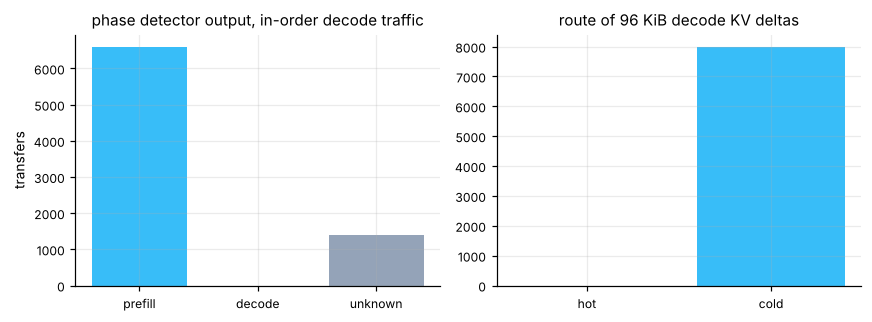

In [4]:
L_LAYERS, STEPS, DELTA = 40, 200, 96 << 10        # Granite-shaped decode: one 96 KiB KV delta per layer per step
clf = WFAClassifier()
phases, routes = Counter(), Counter()
for step in range(STEPS):
    for l in range(L_LAYERS):
        q = clf.classify(f"kv:req1:step{step}:L{l}", DELTA, layer_idx=l)
        phases[clf._current_phase.value] += 1; routes[q.value] += 1
print("phase detector outputs over", STEPS * L_LAYERS, "decode deltas:", dict(phases))
print("routes:", dict(routes), f"-> {routes['cold'] / (STEPS * L_LAYERS):.0%} of decode deltas go cold")
assert phases["decode"] == 0
figp, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].bar([p.value for p in Phase], [phases[p.value] for p in Phase], color=[C["cold"], C["hot"], C["muted"]])
ax[0].set_title("phase detector output, in-order decode traffic"); ax[0].set_ylabel("transfers")
ax[1].bar(["hot", "cold"], [routes["hot"], routes["cold"]], color=[C["hot"], C["cold"]]); ax[1].set_title(f"route of {DELTA >> 10} KiB decode KV deltas")
fig("08_wfa_static_phases", model=True, caption="Proposition 1: DECODE count is 0 by construction of the detector")

## 8b. Train the learned WFA on two model shapes

figure -> docs/figures/08_wfa_training.png


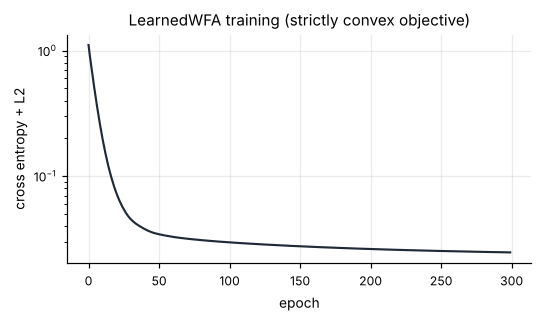

final loss 0.02465865530417291 | monotone non-increasing: True


In [5]:
mix = {"prefill": 0.3, "decode": 0.3, "control": 0.2, "bursty": 0.1, "chunked": 0.1}
train = [
    SyntheticTraceGenerator(seed=SEED + 1).generate(N_TRAIN, mix),
    SyntheticTraceGenerator(seed=SEED + 2, model=ModelShape(layers=24, kv_heads=4, head_dim=128)).generate(N_TRAIN, mix),
]
model = LearnedWFA(epochs=EPOCHS, seed=SEED).fit(train)
figl = plt.figure(figsize=(5, 3)); plt.plot(model.loss_history, color=C["ink"]); plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("cross entropy + L2"); plt.title("LearnedWFA training (strictly convex objective)")
fig("08_wfa_training", model=True)
print("final loss", model.loss_history[-1], "| monotone non-increasing:", bool(np.all(np.diff(model.loss_history) <= 1e-9)))

### Held-out mixes: learned WFA vs static threshold WFAClassifier

Held-out traces use a third model shape (32 layers, head_dim 128) and different pattern mixes. The oracle label is defined in `oracle_label()`: token ids, metadata and decode KV deltas up to 256 KiB are hot; prefill KV over 64 KiB, weights and SSM state are cold; the rest warm. These are synthetic traces, so accuracy here shows the learner and harness work against that oracle, not that the oracle is right for real hardware.

mix | n | learned state acc | learned route acc | learned hot P | learned hot R | static route acc | static hot P | static hot R
base | 4000 | 0.9990 | 0.9990 | 0.9989 | 1.0000 | 0.2607 | 1.0000 | 0.1677
decode-heavy | 4000 | 0.9990 | 0.9990 | 0.9990 | 1.0000 | 0.1713 | 1.0000 | 0.1656
prefill-heavy | 4000 | 0.9995 | 0.9995 | 0.9957 | 1.0000 | 1.0000 | 1.0000 | 1.0000
bursty | 4000 | 0.9988 | 0.9988 | 0.9980 | 1.0000 | 0.4893 | 1.0000 | 0.1705


figure -> docs/figures/08_wfa_heldout.png  |  synthetic oracle; the static classifier misses most hot decode deltas (Proposition 1)


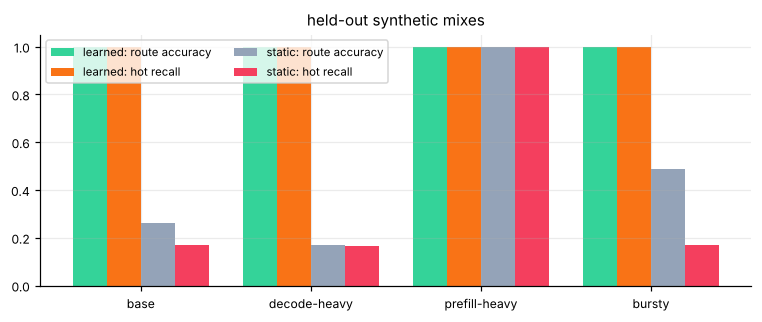

In [6]:
heldout = {
    "base": None,
    "decode-heavy": {"decode": 0.8, "control": 0.2},
    "prefill-heavy": {"prefill": 0.8, "control": 0.1, "weights": 0.1},
    "bursty": {"bursty": 0.7, "chunked": 0.3},
}
rows = []
evals = {}
for i, (name, m) in enumerate(heldout.items()):
    tr = [SyntheticTraceGenerator(seed=SEED + 100 + i, model=ModelShape(layers=32, kv_heads=8, head_dim=128)).generate(N_TEST, m)]
    e, s = evaluate(model, tr), evaluate_static(tr, WFAClassifier())
    evals[name] = (e, s)
    rows.append((name, e["n"], e["state_accuracy"], e["routing_accuracy"], e["hot_precision"], e["hot_recall"],
                 s["routing_accuracy"], s["hot_precision"], s["hot_recall"]))
hdr = ("mix", "n", "learned state acc", "learned route acc", "learned hot P", "learned hot R",
       "static route acc", "static hot P", "static hot R")
print(" | ".join(hdr))
for r in rows:
    print(" | ".join([r[0], str(r[1])] + [f"{x:.4f}" for x in r[2:]]))
figr, ax = plt.subplots(figsize=(7, 3))
xs = np.arange(len(rows)); w = 0.2
ax.bar(xs - 1.5 * w, [r[3] for r in rows], w, color=C["ok"], label="learned: route accuracy")
ax.bar(xs - 0.5 * w, [r[5] for r in rows], w, color=C["hot"], label="learned: hot recall")
ax.bar(xs + 0.5 * w, [r[6] for r in rows], w, color=C["muted"], label="static: route accuracy")
ax.bar(xs + 1.5 * w, [r[8] for r in rows], w, color=C["bad"], label="static: hot recall")
ax.set_xticks(xs); ax.set_xticklabels([r[0] for r in rows]); ax.set_ylim(0, 1.05); ax.legend(ncol=2); ax.set_title("held-out synthetic mixes")
fig("08_wfa_heldout", model=True, caption="synthetic oracle; the static classifier misses most hot decode deltas (Proposition 1)")

figure -> docs/figures/08_wfa_confusion.png


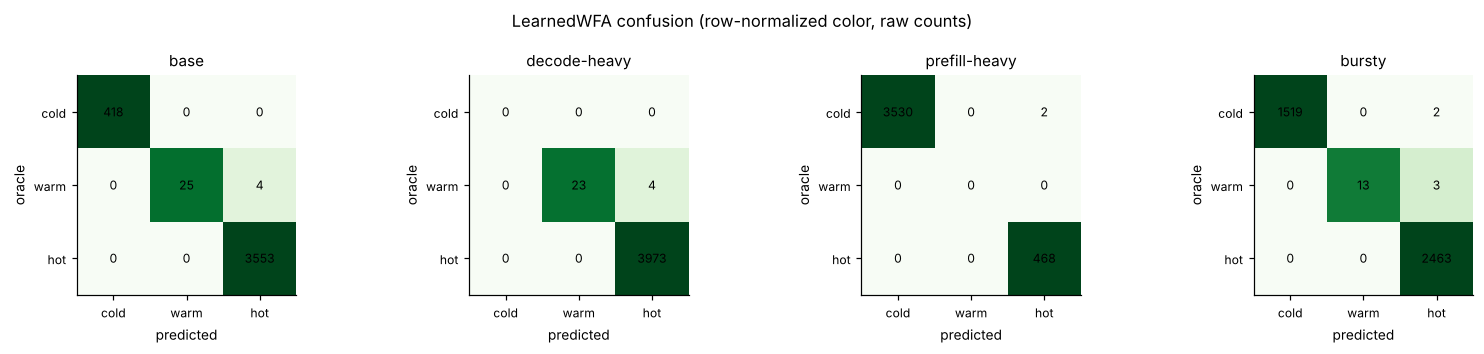

base static binary confusion [[tn, fp], [fn, tp]] = [[447, 0], [2957, 596]]
decode-heavy static binary confusion [[tn, fp], [fn, tp]] = [[27, 0], [3315, 658]]
prefill-heavy static binary confusion [[tn, fp], [fn, tp]] = [[3532, 0], [0, 468]]
bursty static binary confusion [[tn, fp], [fn, tp]] = [[1537, 0], [2043, 420]]


In [7]:
figc, axes = plt.subplots(1, len(evals), figsize=(3.6 * len(evals), 3.2))
for ax, (name, (e, s)) in zip(axes, evals.items()):
    cm = np.asarray(e["confusion_states"], dtype=float)
    cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    ax.imshow(cmn, vmin=0, vmax=1, cmap="Greens"); ax.grid(False)
    for a in range(3):
        for b in range(3):
            ax.text(b, a, int(cm[a, b]), ha="center", va="center", fontsize=8)
    ax.set_xticks(range(3)); ax.set_xticklabels(STATES); ax.set_yticks(range(3)); ax.set_yticklabels(STATES)
    ax.set_xlabel("predicted"); ax.set_ylabel("oracle"); ax.set_title(name)
plt.suptitle("LearnedWFA confusion (row-normalized color, raw counts)")
fig("08_wfa_confusion", model=True)
for name, (e, s) in evals.items():
    print(name, "static binary confusion [[tn, fp], [fn, tp]] =", s["confusion_binary"])

### What the weights learned

For each current state, the logit margin of going **hot** versus **cold**, per standardized feature. Proposition 3 in the write-up: a per-phase size cutoff is a sign change along the `log2_size × phase` interaction columns.

figure -> docs/figures/08_wfa_weights.png


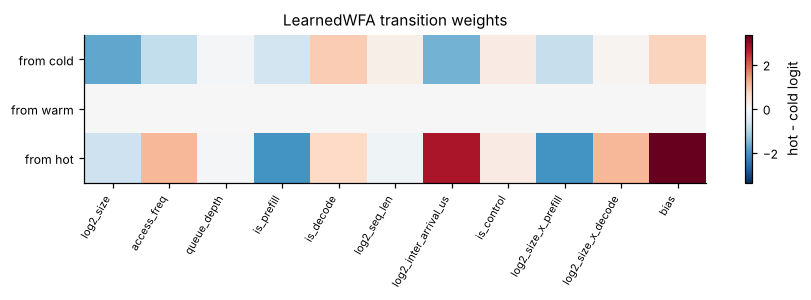

weights -> /tmp/scuffed-local/wfa_policy/vm_learned_wfa_weights.json


In [8]:
W = np.asarray(model.W)
names = list(PHI_NAMES) + ["bias"]
margin = W[:, STATES.index("hot"), :] - W[:, STATES.index("cold"), :]
figw, ax = plt.subplots(figsize=(8, 2.8))
im = ax.imshow(margin, cmap="RdBu_r", vmin=-np.abs(margin).max(), vmax=np.abs(margin).max(), aspect="auto"); ax.grid(False)
ax.set_yticks(range(3)); ax.set_yticklabels([f"from {s}" for s in STATES])
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=7)
plt.colorbar(im, label="hot - cold logit"); ax.set_title("LearnedWFA transition weights")
fig("08_wfa_weights", model=True)
wpath = RESULTS / f"{HOST}_learned_wfa_weights.json"
model.save(str(wpath)); print("weights ->", wpath)

## 9. Default policy on a mixed trace

`middleware/policy/default_policy.json` with the learned WFA registered as classifier `wfa`. Context (GPU memory and link utilization) is swept to show the spill and compress rules fire, and which rule owns each decision.

idle                   routes={'hot': 1347, 'cold': 653} compressed=0
   route set by: {'control-messages-hot': 139, 'prefill-bulk-cold': 640, 'decode-small-kv-hot': 1208, 'default': 13}
link busy              routes={'hot': 1347, 'cold': 653} compressed=484
   route set by: {'control-messages-hot': 139, 'prefill-bulk-cold': 640, 'decode-small-kv-hot': 1208, 'default': 13}


gpu full + link busy   routes={'hot': 1347, 'spill': 476, 'cold': 177} compressed=484
   route set by: {'control-messages-hot': 139, 'spill-bulk-under-gpu-pressure': 476, 'decode-small-kv-hot': 1208, 'default': 10, 'prefill-bulk-cold': 167}


figure -> docs/figures/09_policy_routes.png  |  the spill rule needs gpu_mem_util above its watermark; compress needs link_util >= 0.8


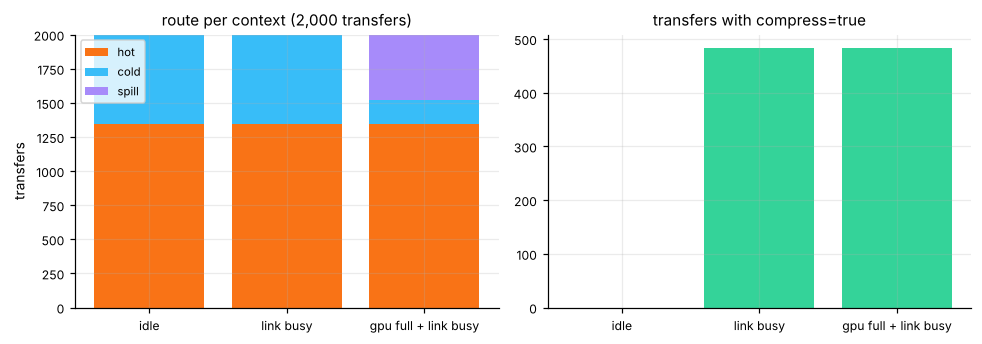

In [9]:
engine = PolicyEngine.default_policy(classifiers={"wfa": model})
trace = SyntheticTraceGenerator(seed=SEED + 7).generate(2000, {"bursty": 0.5, "chunked": 0.3, "decode": 0.2})
contexts = {"idle": {"gpu_mem_util": 0.5, "link_util": 0.1},
            "link busy": {"gpu_mem_util": 0.5, "link_util": 0.9},
            "gpu full + link busy": {"gpu_mem_util": 0.95, "link_util": 0.9}}
policy_summary = {}
for cname, ctx in contexts.items():
    model.reset()
    ds = engine.decide_many([s for s, _ in trace], ctx)
    routes = Counter(d.route for d in ds)
    comp = sum(d.compress for d in ds)
    owners = Counter(d.rules["route"] for d in ds)
    policy_summary[cname] = {"routes": dict(routes), "compressed": comp, "route_owner": dict(owners)}
    print(f"{cname:22s} routes={dict(routes)} compressed={comp}")
    print("   route set by:", dict(owners))
figpo, ax = plt.subplots(1, 2, figsize=(9, 3.2))
names_c = list(contexts); bottom = np.zeros(len(names_c))
for route, col in (("hot", C["hot"]), ("cold", C["cold"]), ("spill", C["spill"])):
    vals = np.array([policy_summary[c]["routes"].get(route, 0) for c in names_c])
    ax[0].bar(names_c, vals, bottom=bottom, color=col, label=route); bottom += vals
ax[0].set_ylabel("transfers"); ax[0].set_title("route per context (2,000 transfers)"); ax[0].legend()
ax[1].bar(names_c, [policy_summary[c]["compressed"] for c in names_c], color=C["ok"]); ax[1].set_title("transfers with compress=true")
fig("09_policy_routes", model=True, caption="the spill rule needs gpu_mem_util above its watermark; compress needs link_util >= 0.8")

In [10]:
model.reset()
examples = [
    SignalVector(size_bytes=48, role="token", phase="decode", tensor_id="tok:1"),
    SignalVector(size_bytes=96 << 10, role="kv", phase="decode", tensor_id="kv:9:3", layer_idx=3, seq_len=2048),
    SignalVector(size_bytes=6 << 20, role="kv", phase="prefill", tensor_id="kv:10:0", layer_idx=0, seq_len=4096),
]
for s in examples:
    d = engine.decide(s, contexts["gpu full + link busy"])
    print(f"--- size={s.size_bytes} role={s.role} phase={s.phase} -> route={d.route} compress={d.compress}")
    print(d.explain())

--- size=48 role=token phase=decode -> route=hot compress=False
[rule control-messages-hot p=100]
  + role='token' in ['metadata', 'token']
  => matched, sets {'route': 'hot', 'compress': False}
  => final
--- size=98304 role=kv phase=decode -> route=hot compress=False
[rule control-messages-hot p=100]
  - role='kv' in ['metadata', 'token']
[rule spill-bulk-under-gpu-pressure p=90]
  - and
    + gpu_mem_util=0.95 >= 0.9
    - size_bytes=98304 > 262144
[rule decode-small-kv-hot p=80]
  + and
    + phase='decode' in ['decode']
    + role='kv' in ['kv']
    + size_bytes=98304 <= 262144
  => matched, sets {'route': 'hot'}
[rule prefill-bulk-cold p=70]
  - and
    - phase='decode' in ['prefill']
[rule compress-bulk-when-link-busy p=60]
  - and
    + link_util=0.9 >= 0.8
    - route='hot' in ['cold', 'spill']
[rule wfa-hot p=30]
  + and
    + classifier wfa -> hot (want hot)
    + size_bytes=98304 <= 262144
  => matched, sets nothing new
[rule tiny-anything-hot p=20]
  - size_bytes=98304 < 4

## 10. PMP controller: decision regions of the implemented rule vs the routing-consistent rule

figure -> docs/figures/10_pmp_regions.png  |  defaults alpha=2, beta=1, mu_H=1e4, mu_C=2e3


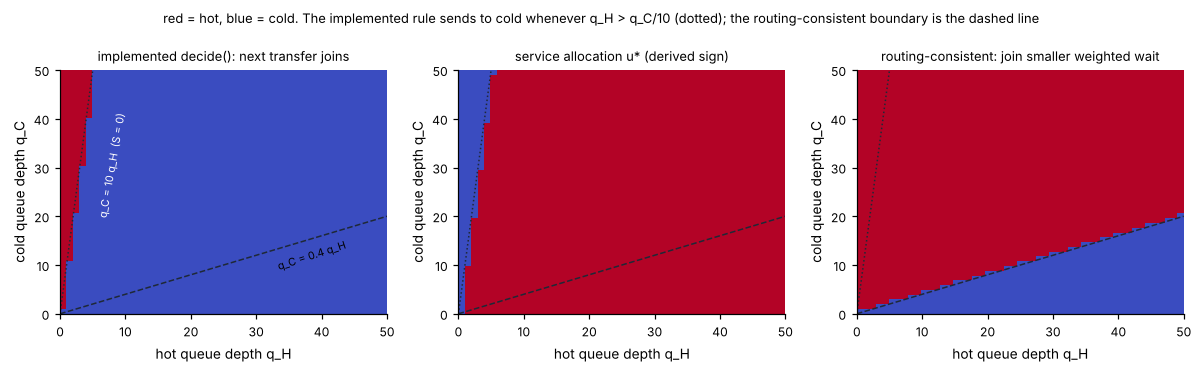

implemented rule picks HOT on 6% of the grid; routing-consistent rule on 79%


In [11]:
pmp = PMPController()                      # defaults: alpha 2, beta 1, mu_hot 1e4, mu_cold 2e3, deadband 0.1
alpha, beta, muH, muC = pmp._alpha, pmp._beta, pmp._mu_hot, pmp._mu_cold
Q = np.arange(0, 51)
impl = np.zeros((len(Q), len(Q))); route_rule = np.zeros_like(impl); serve_rule = np.zeros_like(impl)
for i, qh in enumerate(Q):
    for j, qc in enumerate(Q):
        pmp.reset(); impl[i, j] = 1.0 if pmp.decide(int(qh), int(qc)) == QueueSelection.HOT_QP else 0.0
        S = alpha * qh * muH - beta * qc * muC
        serve_rule[i, j] = 1.0 if S > 0 else 0.0                                   # serve hot when S > 0 (section 4)
        route_rule[i, j] = 1.0 if alpha * qh / muH < beta * qc / muC else 0.0      # join hot when its weighted wait is smaller
figd, ax = plt.subplots(1, 3, figsize=(11, 3.4))
for a_, Z, t_ in zip(ax, (impl, serve_rule, route_rule),
                     ("implemented decide(): next transfer joins", "service allocation u* (derived sign)", "routing-consistent: join smaller weighted wait")):
    a_.imshow(Z.T, origin="lower", extent=[Q[0], Q[-1], Q[0], Q[-1]], cmap="coolwarm", vmin=0, vmax=1, aspect="auto"); a_.grid(False)
    a_.set_xlabel("hot queue depth q_H"); a_.set_ylabel("cold queue depth q_C"); a_.set_title(t_, fontsize=8.5)
    a_.plot(Q, 10 * Q, color=C["ink"], ls=":", lw=1); a_.plot(Q, 0.4 * Q, color=C["ink"], ls="--", lw=1)
    a_.set_xlim(Q[0], Q[-1]); a_.set_ylim(Q[0], Q[-1])
ax[0].text(5.5, 20, "q_C = 10 q_H  (S = 0)", fontsize=7, rotation=80, color="white"); ax[0].text(33, 9, "q_C = 0.4 q_H", fontsize=7, rotation=18)
plt.suptitle("red = hot, blue = cold. The implemented rule sends to cold whenever q_H > q_C/10 (dotted); the routing-consistent boundary is the dashed line", fontsize=8.5)
fig("10_pmp_regions", model=True, caption="defaults alpha=2, beta=1, mu_H=1e4, mu_C=2e3")
print(f"implemented rule picks HOT on {impl.mean():.0%} of the grid; routing-consistent rule on {route_rule.mean():.0%}")

### Simulating both rules on Poisson arrivals

Identical transfers arrive at rate $\lambda$; each is routed by the rule under test; queue $i$ completes work at rate $\mu_i$. The mean wait per rule follows from the time-average queue length (Little's law). The derivation in the write-up says the implemented rule starves the fast queue; this checks it.

implemented decide()                 mean q_H     0.5  mean q_C    17.0  mean wait   1.76 ms  sent hot 80%
routing-consistent (weighted wait)   mean q_H     1.6  mean q_C     1.3  mean wait   0.28 ms  sent hot 80%


join shortest expected wait          mean q_H     1.7  mean q_C     0.7  mean wait   0.24 ms  sent hot 82%


figure -> docs/figures/10_pmp_simulation.png  |  synthetic; the point is the ordering, not the numbers


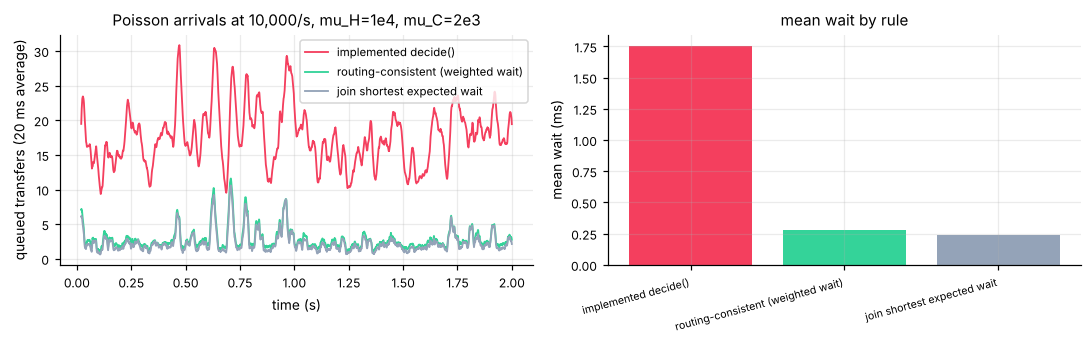

In [12]:
def simulate(rule, lam=10000.0, T=2.0, dt=1e-4, seed=0):
    rng = np.random.default_rng(seed); qh = qc = 0.0; hist = []; sent_hot = 0; n = 0
    carry_h = carry_c = 0.0
    for _ in range(int(T / dt)):
        for _ in range(rng.poisson(lam * dt)):
            n += 1
            if rule(qh, qc): qh += 1; sent_hot += 1
            else: qc += 1
        carry_h += muH * dt; k = int(carry_h); carry_h -= k; qh = max(0.0, qh - k)
        carry_c += muC * dt; k = int(carry_c); carry_c -= k; qc = max(0.0, qc - k)
        hist.append((qh, qc))
    h = np.array(hist)
    return {"mean_qH": h[:, 0].mean(), "mean_qC": h[:, 1].mean(), "mean_wait_ms": (h.sum(axis=1).mean() / lam) * 1e3,
            "frac_hot": sent_hot / max(n, 1), "hist": h, "lam": lam}
ctrl = PMPController()
rules = {
    "implemented decide()": lambda qh, qc: ctrl.decide(int(qh), int(qc)) == QueueSelection.HOT_QP,
    "routing-consistent (weighted wait)": lambda qh, qc: alpha * qh / muH < beta * qc / muC,
    "join shortest expected wait": lambda qh, qc: qh / muH <= qc / muC,
}
sim = {}
for name, r in rules.items():
    ctrl.reset(); sim[name] = simulate(r)
    print(f"{name:36s} mean q_H {sim[name]['mean_qH']:7.1f}  mean q_C {sim[name]['mean_qC']:7.1f}  mean wait {sim[name]['mean_wait_ms']:6.2f} ms  sent hot {sim[name]['frac_hot']:.0%}")
figs, ax = plt.subplots(1, 2, figsize=(10, 3.2))
t = np.arange(len(sim[name]["hist"])) * 1e-4
win = 200                                                      # 20 ms moving average
for (name, s_), col in zip(sim.items(), (C["bad"], C["ok"], C["muted"])):
    tot = s_["hist"][:, 0] + s_["hist"][:, 1]
    ax[0].plot(t[win - 1:], np.convolve(tot, np.ones(win) / win, mode="valid"), color=col, lw=1.2, label=name)
ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("queued transfers (20 ms average)"); ax[0].set_title(f"Poisson arrivals at {sim[name]['lam']:,.0f}/s, mu_H=1e4, mu_C=2e3"); ax[0].legend()
ax[1].bar(list(sim), [s_["mean_wait_ms"] for s_ in sim.values()], color=[C["bad"], C["ok"], C["muted"]]); ax[1].set_ylabel("mean wait (ms)")
plt.setp(ax[1].get_xticklabels(), rotation=15, ha="right", fontsize=7); ax[1].set_title("mean wait by rule")
fig("10_pmp_simulation", model=True, caption="synthetic; the point is the ordering, not the numbers")

## Cluster mode: replay real signal dumps

Record signals on the cluster with `Telemetry.observe(SignalVector(...))` in the transport path, then dump them one JSON object per line:

```python
from dataclasses import asdict
with open(f"benchmarks/results/telemetry/{host}_signals.jsonl", "w") as f:
    for s in tel.signals():
        f.write(json.dumps(asdict(s)) + "\n")
```

Labels for real traffic come from `latency_label(threshold_us)` (role plus measured completion latency), since there is no oracle.

In [13]:
import glob, math
real = {}
files = sorted(glob.glob(str(ROOT / SIGNAL_GLOB), recursive=True)) if MODE == "cluster" else []
if not files:
    print("no signal dumps found" + (" (local mode skips this)" if MODE == "local" else f" under {SIGNAL_GLOB}"))
for fp in files:
    tel = Telemetry(node=Path(fp).stem)
    for line in open(fp):
        d = json.loads(line)
        d = {k: (float("nan") if v is None and k in ("completion_us", "inter_arrival_us") else v) for k, v in d.items()}
        tel.observe(SignalVector(**d))
    traces = from_telemetry(tel, latency_label(threshold_us=50.0))
    e, s = evaluate(model, traces), evaluate_static(traces, WFAClassifier())
    real[Path(fp).name] = {"learned": e, "static": s}
    print(Path(fp).name, "n=", e["n"], "learned route acc", round(e["routing_accuracy"], 4),
          "static route acc", round(s["routing_accuracy"], 4))

no signal dumps found (local mode skips this)


In [14]:
save("wfa_policy", {
    "synthetic": True,
    "static_phase_counts": dict(phases), "static_decode_routes": dict(routes),
    "train_events": sum(len(t) for t in train), "epochs": EPOCHS, "seed": SEED,
    "heldout": {k: {"learned": v[0], "static": v[1]} for k, v in evals.items()},
    "policy": policy_summary, "real_signal_replays": real,
    "pmp_simulation": {k: {kk: vv for kk, vv in v.items() if kk != "hist"} for k, v in sim.items()},
})

wrote /tmp/scuffed-local/wfa_policy/vm_wfa_policy.json


PosixPath('/tmp/scuffed-local/wfa_policy/vm_wfa_policy.json')